In [1]:
import sys
sys.path.append("../src")  # pour pouvoir importer nos fichiers de src/

import pandas as pd
from sklearn.model_selection import train_test_split

from data import charger

df = charger()

# Séparation des variables explicatives (X) et de la cible (y)
X = df.drop(columns="Churn")
y = df["Churn"]

In [2]:
# 80 % pour entraîner, 20 % pour tester
# stratify=y : garde le même taux de churn (26,5 %) dans les deux jeux
# random_state : rend le découpage reproductible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(f"Churn train : {y_train.mean():.3f} | Churn test : {y_test.mean():.3f}")

(5634, 19) (1409, 19)
Churn train : 0.265 | Churn test : 0.265


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# On sépare les colonnes selon leur type
var_num = ["tenure", "MonthlyCharges", "TotalCharges"]
var_cat = [c for c in X.columns if c not in var_num]

# Chaque groupe de colonnes reçoit son traitement
preparation = ColumnTransformer([
    ("num", StandardScaler(), var_num),                  # moyenne 0, écart-type 1
    ("cat", OneHotEncoder(drop="if_binary"), var_cat),   # une colonne 0/1 par modalité
])

print(var_cat)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Le pipeline enchaîne la préparation et le modèle :
# la préparation apprend uniquement sur le train, puis s'applique telle quelle au test
modele = Pipeline([
    ("prep", preparation),
    ("clf", LogisticRegression(max_iter=1000)),
])

modele.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

# Prédictions : classe (0/1) et probabilité de churn
y_pred = modele.predict(X_test)
y_proba = modele.predict_proba(X_test)[:, 1]

# Précision, rappel et F1 pour chaque classe
print(classification_report(y_test, y_pred, digits=3))

# Matrice de confusion : [[vrais négatifs, faux positifs], [faux négatifs, vrais positifs]]
print(confusion_matrix(y_test, y_pred))

# Scores qui ne dépendent pas du seuil de 0,5
print(f"ROC-AUC : {roc_auc_score(y_test, y_proba):.3f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_proba):.3f}")

              precision    recall  f1-score   support

           0      0.849     0.895     0.871      1035
           1      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409

[[926 109]
 [165 209]]
ROC-AUC : 0.842
PR-AUC  : 0.634


In [6]:
# class_weight="balanced" : chaque churner pèse environ 2,8 fois plus
# (ratio 73,5 % / 26,5 %), pour que le modèle ne néglige plus la classe minoritaire
modele_eq = Pipeline([
    ("prep", preparation),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
modele_eq.fit(X_train, y_train)

y_pred_eq = modele_eq.predict(X_test)
y_proba_eq = modele_eq.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_eq, digits=3))
print(confusion_matrix(y_test, y_pred_eq))
print(f"ROC-AUC : {roc_auc_score(y_test, y_proba_eq):.3f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_proba_eq):.3f}")

              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

[[747 288]
 [ 81 293]]
ROC-AUC : 0.841
PR-AUC  : 0.633


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Ratio non-churners / churners, pour pondérer XGBoost comme les autres (environ 2,8)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# 4 modèles, tous pondérés pour compenser le déséquilibre
modeles = {
    "Logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Arbre": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
                                    class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             scale_pos_weight=ratio, random_state=42),
}

# 5 plis, chacun gardant 26,5 % de churners
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultats = []
for nom, clf in modeles.items():
    pipe = Pipeline([("prep", preparation), ("clf", clf)])
    # PR-AUC : la métrique adaptée quand la classe qui nous intéresse est minoritaire
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    resultats.append({"modele": nom, "pr_auc_moy": scores.mean(), "ecart_type": scores.std()})

pd.DataFrame(resultats).sort_values("pr_auc_moy", ascending=False).round(3)

,modele,pr_auc_moy,ecart_type
3,XGBoost,0.667,0.022
2,Random Forest,0.663,0.021
0,Logistique,0.660,0.020
1,Arbre,0.616,0.029


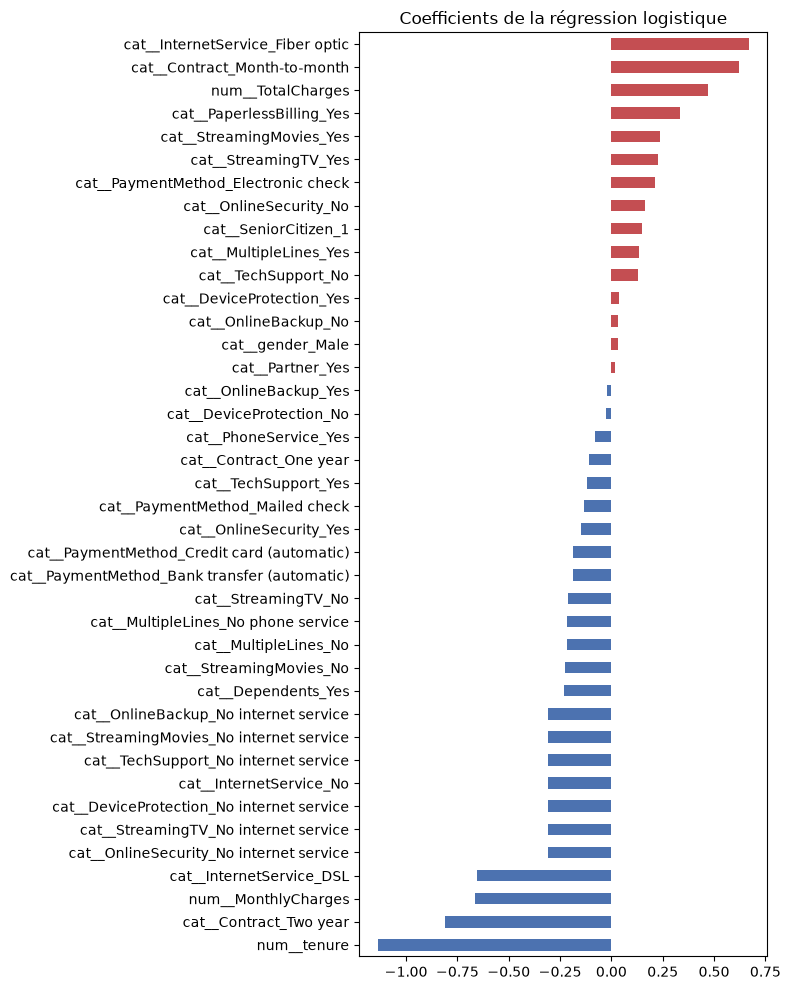

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Noms des 40 colonnes après préparation (ex : "cat__Contract_Two year")
noms = modele_eq.named_steps["prep"].get_feature_names_out()

# Un coefficient par colonne, triés du plus négatif au plus positif
coefs = pd.Series(modele_eq.named_steps["clf"].coef_[0], index=noms).sort_values()

# Rouge = augmente le risque, bleu = le diminue
fig, ax = plt.subplots(figsize=(8, 10))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "#C44E52", "#4C72B0"))
ax.set_title("Coefficients de la régression logistique")
plt.tight_layout()
plt.show()

In [9]:
# Même préparation, mais sans TotalCharges
# (les colonnes non listées sont ignorées par le ColumnTransformer)
var_num_v2 = ["tenure", "MonthlyCharges"]
preparation_v2 = ColumnTransformer([
    ("num", StandardScaler(), var_num_v2),
    ("cat", OneHotEncoder(drop="if_binary"), var_cat),
])

pipe_v2 = Pipeline([
    ("prep", preparation_v2),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# Même validation croisée que tout à l'heure, pour comparer à 0,660
scores_v2 = cross_val_score(pipe_v2, X_train, y_train, cv=cv, scoring="average_precision")
print(f"Sans TotalCharges : {scores_v2.mean():.3f} ± {scores_v2.std():.3f}")

Sans TotalCharges : 0.658 ± 0.019


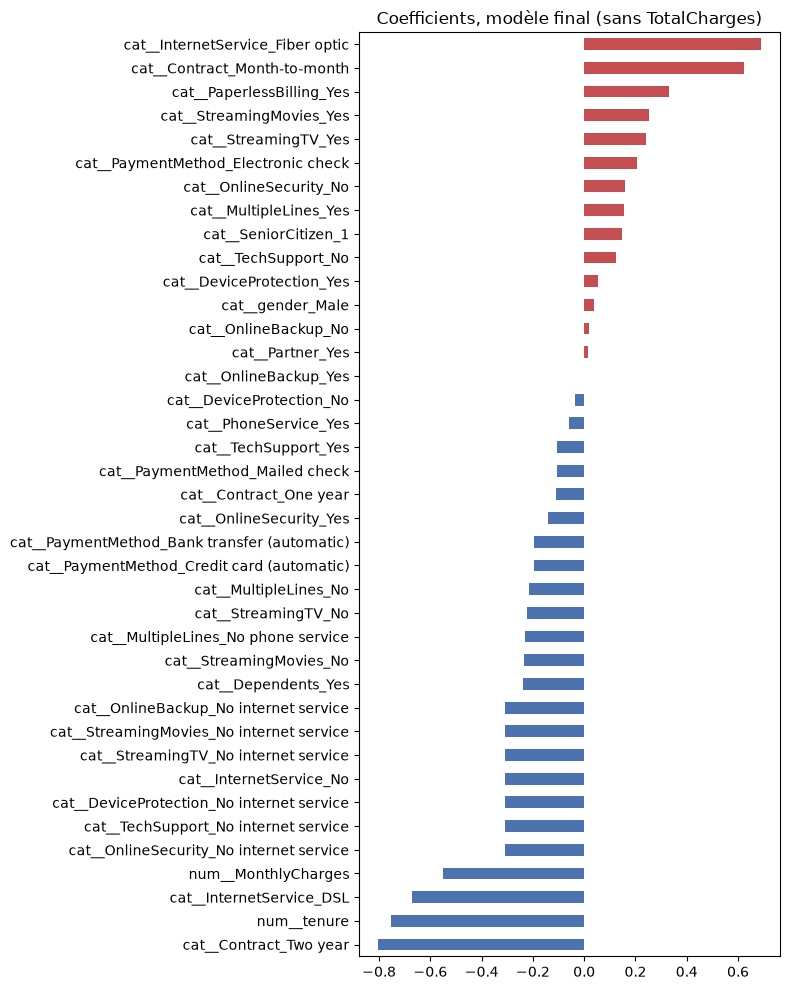

num__tenure           -0.754193
num__MonthlyCharges   -0.552469
dtype: float64

In [10]:
# On entraîne la version finale sur tout le train
pipe_v2.fit(X_train, y_train)

noms_v2 = pipe_v2.named_steps["prep"].get_feature_names_out()
coefs_v2 = pd.Series(pipe_v2.named_steps["clf"].coef_[0], index=noms_v2).sort_values()

fig, ax = plt.subplots(figsize=(8, 10))
coefs_v2.plot.barh(ax=ax, color=np.where(coefs_v2 > 0, "#C44E52", "#4C72B0"))
ax.set_title("Coefficients, modèle final (sans TotalCharges)")
plt.tight_layout()
plt.show()

# Les deux variables numériques, pour vérifier le sens de leur effet
coefs_v2[["num__tenure", "num__MonthlyCharges"]]

In [11]:
# Hypothèses de travail (à ajuster)
COUT_OFFRE = 50
TAUX_SUCCES = 0.30
MOIS_GAGNES = 12

# Probabilités sur le jeu de test (modèle final)
proba = pipe_v2.predict_proba(X_test)[:, 1]
mensuel = X_test["MonthlyCharges"].to_numpy()
churn = y_test.to_numpy()

lignes = []
for seuil in np.arange(0.1, 0.91, 0.05):
    contacte = proba >= seuil                    # clients ciblés par la campagne
    vrais_churners = contacte & (churn == 1)     # ceux qui allaient vraiment partir
    gain = (TAUX_SUCCES * MOIS_GAGNES * mensuel[vrais_churners]).sum()
    cout = COUT_OFFRE * contacte.sum()
    lignes.append({"seuil": round(seuil, 2), "contactes": contacte.sum(),
                   "churners_touches": vrais_churners.sum(), "gain_net": round(gain - cout)})

seuils = pd.DataFrame(lignes)
seuils

,seuil,contactes,churners_touches,gain_net
0,0.10,1099,371,42266
1,0.15,998,365,45494
2,0.20,921,359,47905
3,0.25,864,351,48569
4,0.30,810,348,50418
5,0.35,754,336,50707
6,0.40,687,321,51647
7,0.45,631,305,51734
8,0.50,573,290,51075
9,0.55,530,278,50394


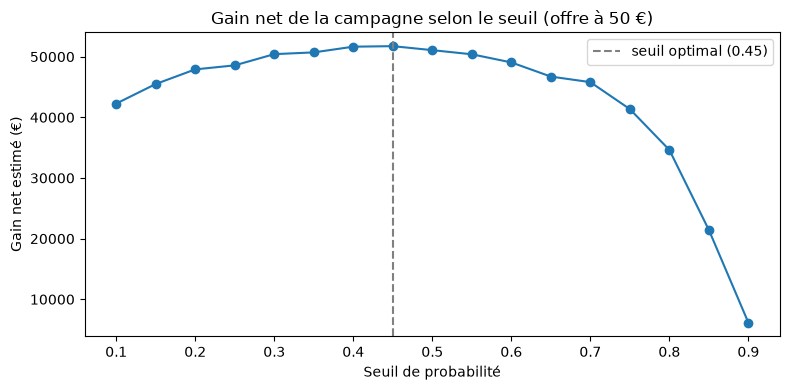

In [12]:
from pathlib import Path

# Crée le dossier des figures s'il n'existe pas
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

# Seuil qui maximise le gain, calculé à partir du tableau
seuil_opt = seuils.loc[seuils["gain_net"].idxmax(), "seuil"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seuils["seuil"], seuils["gain_net"], marker="o")
ax.axvline(seuil_opt, ls="--", color="grey", label=f"seuil optimal ({seuil_opt})")
ax.set_xlabel("Seuil de probabilité")
ax.set_ylabel("Gain net estimé (€)")
ax.set_title(f"Gain net de la campagne selon le seuil (offre à {COUT_OFFRE} €)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/gain_par_seuil.png", dpi=120)
plt.show()